In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

In [3]:
# NOTE: If you get errors importing, run the following !pip... line,
# then restart your session (from Runtime menu) and comment out the pip line.
#!pip install gensim

import gensim.downloader as api

# download the wikipedia and twitter models
wiki = api.load('glove-wiki-gigaword-50')
twit = api.load('glove-twitter-50')

In [4]:
dir(twit)

['__class__',
 '__contains__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getitem__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__len__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setitem__',
 '__sizeof__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_adapt_by_suffix',
 '_load_specials',
 '_log_evaluate_word_analogies',
 '_save_specials',
 '_smart_save',
 '_upconvert_old_d2vkv',
 '_upconvert_old_vocab',
 'add_lifecycle_event',
 'add_vector',
 'add_vectors',
 'allocate_vecattrs',
 'closer_than',
 'cosine_similarities',
 'distance',
 'distances',
 'doesnt_match',
 'evaluate_word_analogies',
 'evaluate_word_pairs',
 'expandos',
 'fill_norms',
 'get_index',
 'get_mean_vector',
 'get_normed_vectors',
 'get_vecattr',
 'get_vector',
 'has_index_for',
 

In [5]:
# embedding matrix dimensions
print(f'Wikipedia model has {wiki.vectors.shape[0]:,} words and {wiki.vectors.shape[1]} dimensions')
print(f'Twitter model has {twit.vectors.shape[0]:,} words and {twit.vectors.shape[1]} dimensions')

Wikipedia model has 400,000 words and 50 dimensions
Twitter model has 1,193,514 words and 50 dimensions


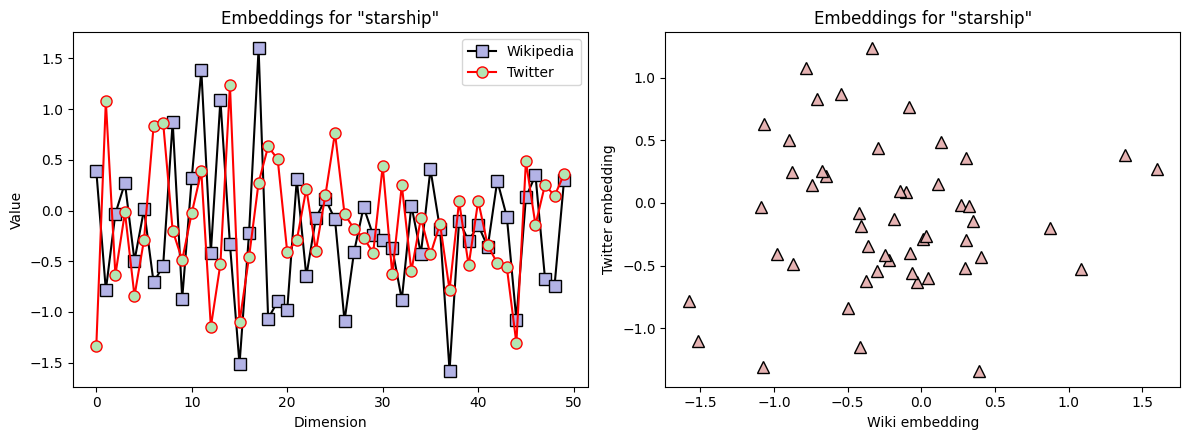

In [7]:
targetword = 'starship'

_,axs = plt.subplots(1,2,figsize=(12,4.5))
axs[0].plot(wiki[targetword],'ks-',markerfacecolor=[.7,.7,.9],markersize=8,label='Wikipedia')
axs[0].plot(twit[targetword],'ro-',markerfacecolor=[.7,.9,.7],markersize=8,label='Twitter')
axs[0].set(xlabel='Dimension',ylabel='Value',title=f'Embeddings for "{targetword}"')
axs[0].legend()

axs[1].plot(wiki[targetword],twit[targetword],'k^',markerfacecolor=[.9,.7,.7],markersize=8)
axs[1].set(xlabel='Wiki embedding',ylabel='Twitter embedding',title=f'Embeddings for "{targetword}"')

plt.tight_layout()
plt.show()

In [ ]:
word1='table'
word2 = 'chair'


array([-0.36661 ,  1.0584  , -0.65378 ,  0.17674 ,  1.0605  , -0.72541 ,
       -0.009721,  0.07969 , -0.4649  , -0.74347 , -0.64147 , -0.16837 ,
       -0.48926 ,  0.56673 ,  0.73102 ,  0.18387 ,  0.34366 , -0.19158 ,
        0.066052, -1.3434  ,  0.50813 , -0.21998 ,  0.46182 ,  0.65796 ,
       -0.19109 , -0.6428  , -0.14994 ,  0.74716 , -0.23347 , -0.16557 ,
        2.8593  ,  0.60577 , -0.63465 ,  0.45448 ,  0.14856 ,  0.53445 ,
        0.27442 ,  1.0104  ,  0.079507, -0.44915 ,  0.46796 , -0.49001 ,
       -0.20323 ,  0.65496 ,  0.16845 ,  0.50674 ,  0.62557 ,  0.071343,
        0.61898 , -0.99744 ], dtype=float32)

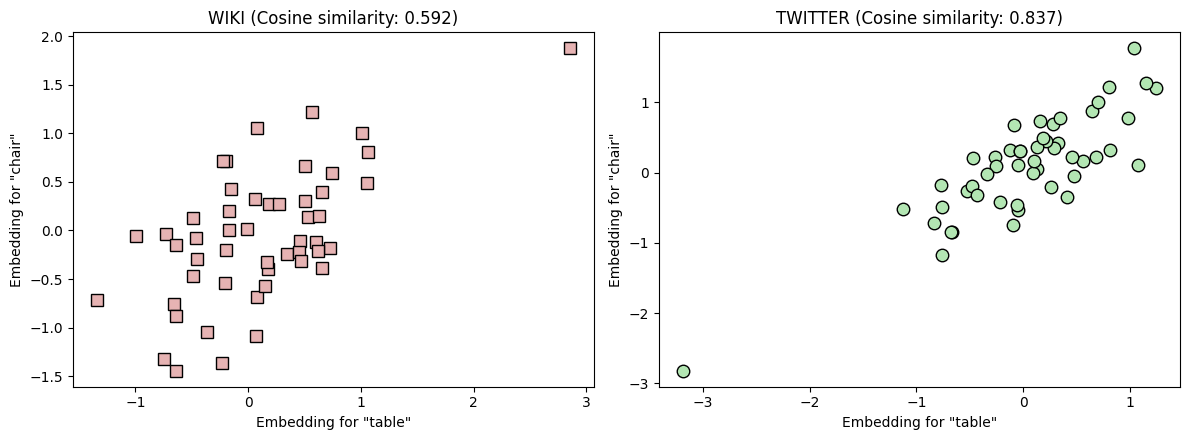

In [9]:
# scatter plot for wiki
_,axs = plt.subplots(1,2,figsize=(12,4.5))
axs[0].plot(wiki[word1],wiki[word2],'ks',markersize=9,markerfacecolor=[.9,.7,.7])
axs[0].set(xlabel=f'Embedding for "{word1}"',ylabel=f'Embedding for "{word2}"',
           title=f'WIKI (Cosine similarity: {wiki.similarity(word1,word2):.3f})')


# scatter plot for twitter
axs[1].plot(twit[word1],twit[word2],'ko',markersize=9,markerfacecolor=[.7,.9,.7])
axs[1].set(xlabel=f'Embedding for "{word1}"',ylabel=f'Embedding for "{word2}"',
           title=f'TWITTER (Cosine similarity: {twit.similarity(word1,word2):.3f})')

plt.tight_layout()
plt.show()

# geting the most similar words on both embeddings

In [19]:
print(f'Top 10 most similar word to "battery" in wiki is \n {wiki.most_similar('battery', topn=10)}')
print(f'Top 10 most similar word to "battery" in twit is \n {twit.most_similar('battery', topn=10)}')


Top 10 most similar word to "battery" in wiki is 
 [('batteries', 0.8322107195854187), ('rechargeable', 0.7258116602897644), ('lithium-ion', 0.7082582116127014), ('weapon', 0.6928435564041138), ('machine', 0.6787962913513184), ('lead-acid', 0.6765270233154297), ('device', 0.6705914735794067), ('anti-aircraft', 0.6586135029792786), ('gun', 0.6580089330673218), ('electric', 0.6576830744743347)]
Top 10 most similar word to "battery" in twit is 
 [('charger', 0.8720738887786865), ('cell', 0.8216446042060852), ('batteries', 0.8167192935943604), ('laptop', 0.8139174580574036), ('batt', 0.8042665719985962), ('charging', 0.7880637049674988), ('replacement', 0.7854103446006775), ('adapter', 0.7587377429008484), ('phone', 0.7571932077407837), ('charge', 0.749850869178772)]


In [20]:
print('10 words most similar to "battery" in wiki:')
for w,cs in wiki.most_similar('battery'):
  print(f' {w:>15} with similarity {cs:.4f}')

print('\nAnd in twitter:')
for w,cs in twit.most_similar('battery'):
  print(f' {w:>15} with similarity {cs:.4f}')

10 words most similar to "battery" in wiki:
       batteries with similarity 0.8322
    rechargeable with similarity 0.7258
     lithium-ion with similarity 0.7083
          weapon with similarity 0.6928
         machine with similarity 0.6788
       lead-acid with similarity 0.6765
          device with similarity 0.6706
   anti-aircraft with similarity 0.6586
             gun with similarity 0.6580
        electric with similarity 0.6577

And in twitter:
         charger with similarity 0.8721
            cell with similarity 0.8216
       batteries with similarity 0.8167
          laptop with similarity 0.8139
            batt with similarity 0.8043
        charging with similarity 0.7881
     replacement with similarity 0.7854
         adapter with similarity 0.7587
           phone with similarity 0.7572
          charge with similarity 0.7499
